# 02 · Visualising the data with matplotlib and seaborn

**Series:** Exploring the ZTF Bright Transient Survey to find Type Ia supernovae
1. Loading & cleaning with pandas
2. **Visualising with matplotlib & seaborn** ← you are here
3. Finding patterns & a first Ia classifier

---

Notebook 1 summarised the data in tables. Here the same questions get answered with **pictures**, which show the *shape* of the data: clusters, cut-offs, trends and outliers that summary numbers hide.

| Library | Role |
|---|---|
| **matplotlib** | Python's base plotting library. Full control over every element. |
| **seaborn** | Built on matplotlib. Statistical plots (distributions, categories, pair plots) from a DataFrame in one line. |
| **plotly** (bonus) | Interactive plots you can zoom, pan and hover over. |
| **astropy** | Cosmology calculations for the Hubble diagram. |

Each plot is introduced with the **question** it answers, and ends with **what it shows**.

## 0 · Setup

`ztf_style.py` (in the project folder) holds the shared colours and chart settings, so every figure in the series looks consistent:

* **Blue = SN Ia, orange = other supernovae, aqua = non-supernovae.** A class keeps its colour in every plot. These three colours were checked to stay distinguishable for colour-blind readers.
* When one group is the story, it's coloured and everything else is grey.
* Gridlines are light and thin so the data stands out.

`ztf_style.save(fig, "name")` writes each figure as a PNG into `figures/`, ready for slides.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import ztf_style
from ztf_style import CLASS3_COLORS, CLASS3_ORDER, IA, INK, INK_2, MUTED, GRID

ztf_style.use()

df = pd.read_parquet("data/bts_clean.parquet")
classified = df[df["class3"].notna()].copy()
print(f"{len(df):,} objects, {len(classified):,} classified")

11,204 objects, 7,834 classified


## 1 · matplotlib basics: Figure and Axes

Every matplotlib plot has two core objects:

* the **Figure**, the whole image (it can hold several plots);
* one or more **Axes**, each an individual plot with its own x/y axis, title and data.

`fig, ax = plt.subplots()` creates both. Everything is then done through methods on `ax`: `ax.hist(...)`, `ax.set_xlabel(...)`, and so on. This *object-oriented* style is clearer than the older `plt.xxx()` style once a figure holds more than one plot.

**Question:** How bright are the transients in the catalogue?

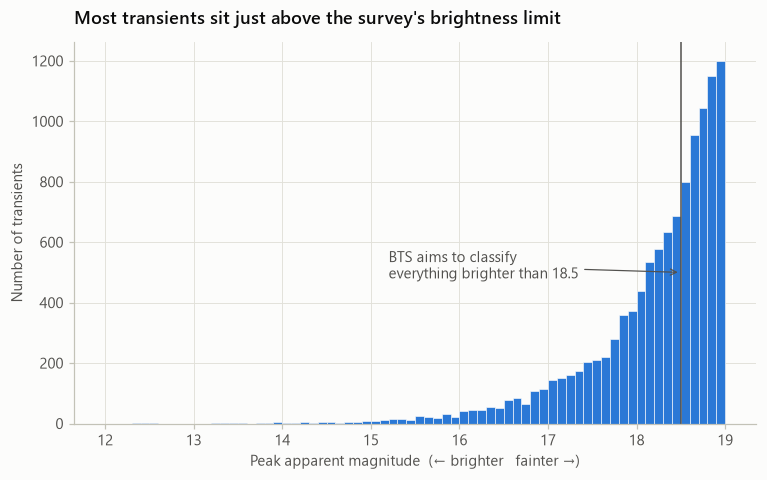

In [2]:
fig, ax = plt.subplots()

ax.hist(df["peakmag"], bins=np.arange(12, 19.05, 0.1), color=IA, edgecolor=ztf_style.SURFACE, linewidth=0.4)
ax.axvline(18.5, color=INK_2, linewidth=1)
ax.annotate("BTS aims to classify\neverything brighter than 18.5",
            xy=(18.5, 500), xytext=(15.2, 480), color=INK_2,
            arrowprops=dict(arrowstyle="->", color=INK_2, linewidth=0.8))

ax.set_xlabel("Peak apparent magnitude  (← brighter   fainter →)")
ax.set_ylabel("Number of transients")
ax.set_title("Most transients sit just above the survey's brightness limit")
ztf_style.save(fig, "02_peakmag_hist");

**What it shows:** the number of objects climbs steeply towards fainter magnitudes and then stops dead at 19. The cut-off is not physics, it's the survey's **selection limit**. Anything fainter is excluded.

Why the steep climb? Fainter usually means farther away, and the volume of space grows as distance cubed. That gives a classic prediction for a survey looking out into a uniform universe: the number of objects brighter than magnitude *m* grows as **N(<m) ∝ 10^(0.6 m)**. On a log axis that's a straight line, so it's easy to check:

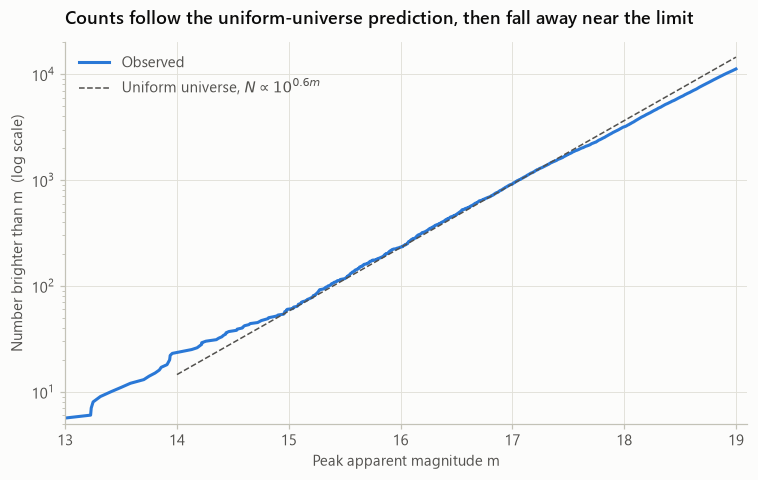

In [3]:
mags = np.sort(df["peakmag"].to_numpy())
cumulative = np.arange(1, len(mags) + 1)            # N(< m) for each sorted magnitude

fig, ax = plt.subplots()
ax.plot(mags, cumulative, color=IA, label="Observed")

ref_m = np.linspace(14, 19, 50)
anchor = np.searchsorted(mags, 17.0)                 # pin the reference line at m = 17
ax.plot(ref_m, anchor * 10 ** (0.6 * (ref_m - 17.0)), color=INK_2, linewidth=1, linestyle="--",
        label=r"Uniform universe, $N \propto 10^{0.6m}$")

ax.set_yscale("log")
ax.set_xlim(13, 19.1)
ax.set_ylim(5, 2e4)
ax.set_xlabel("Peak apparent magnitude m")
ax.set_ylabel("Number brighter than m  (log scale)")
ax.set_title("Counts follow the uniform-universe prediction, then fall away near the limit")
ax.legend(loc="upper left")
ztf_style.save(fig, "02_cumulative_counts");

**What it shows:** between magnitudes ~15 and ~17.5 the observed curve runs parallel to the 0.6 slope, as a magnitude-limited sample of a uniform universe should. Fainter than ~17.5 it bends below the line: the survey starts missing objects there (it is *incomplete*). At the very bright end there are only a handful of objects, so the curve is noisy. This matters for ML because **the classifier will see a sample biased towards intrinsically bright objects**, and fainter Ia will be under-represented.

## 2 · Bar charts: what kinds of object are there?

**Question:** How many of each class are there, and how dominant are Type Ia?

For a "how many of each category" question, a **horizontal bar chart** is easiest to read: the labels sit horizontally and the bars are sorted by size. Only the class of interest is coloured.

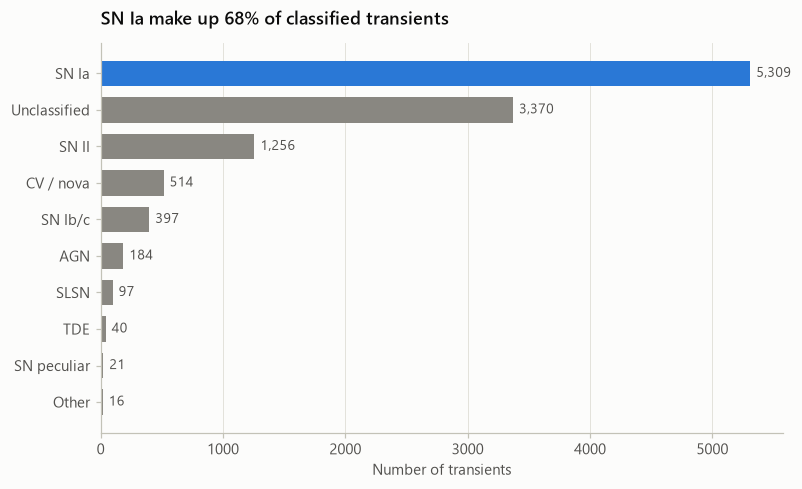

In [7]:
# Convert counts to percentages
#counts = df["subclass"].value_counts(normalize=True).mul(100).round(2).sort_values()
counts = df["subclass"].value_counts().sort_values()
colors = [IA if name == "SN Ia" else MUTED for name in counts.index]

fig, ax = plt.subplots(figsize=(8, 4.6))
bars = ax.barh(counts.index, counts.values, color=colors, height=0.7)
ax.bar_label(bars, labels=[f"{v:,}" for v in counts.values], padding=4, color=INK_2, fontsize=9)

ax.grid(axis="y", visible=False)          # horizontal gridlines add nothing to a horizontal bar chart
ax.set_xlabel("Number of transients")
ia_share = (classified["is_ia"]).mean()
ax.set_title(f"SN Ia make up {ia_share:.0%} of classified transients")
ztf_style.save(fig, "02_class_counts");

**What it shows:** SN Ia outnumber every other class combined, about 2 to 1 among classified objects. That's no accident. They're the most luminous *common* supernova, so a magnitude-limited survey sees them out to the largest distances, and they dominate.

**For ML:** a model that answers "Ia" for everything would already be right 68% of the time. Any real classifier has to beat that **baseline**.

## 3 · Time series: discoveries over time

pandas can **resample** a time-indexed table, much like `groupby` but for time bins. `"MS"` means "month start", so each bin is a calendar month.

**Question:** How steady is the discovery rate, and are recent objects still waiting to be classified?

In [5]:
timeline = df.set_index("discdate").sort_index().loc["2018-04":"2026-07"]   # full months of survey operations

monthly = pd.DataFrame({
    "All transients": timeline.resample("MS").size(),
    "SN Ia":          timeline[timeline["is_ia"] == True].resample("MS").size(),
    "Unclassified":   timeline[timeline["class3"].isna()].resample("MS").size(),
}).fillna(0)
monthly.tail()

,All transients,SN Ia,Unclassified
discdate,,,
2026-03-01,36,0.0,35
2026-04-01,64,0.0,64
2026-05-01,46,0.0,45
2026-06-01,41,0.0,41
2026-07-01,19,0.0,19


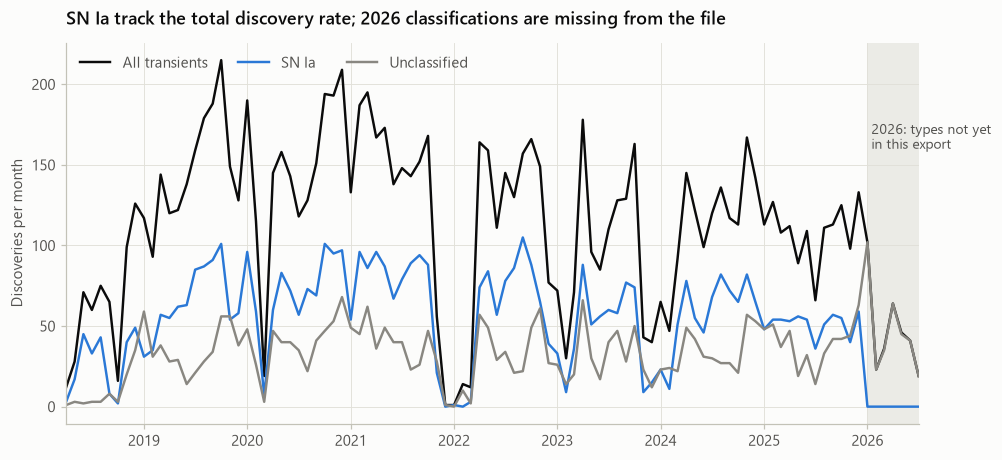

In [6]:
line_colors = {"All transients": INK, "SN Ia": IA, "Unclassified": MUTED}

fig, ax = plt.subplots(figsize=(10, 4.5))
for name, color in line_colors.items():
    ax.plot(monthly.index, monthly[name], color=color, linewidth=1.6, label=name)

ax.axvspan(pd.Timestamp("2026-01-01"), monthly.index[-1], color=GRID, alpha=0.6, linewidth=0)
ax.annotate("2026: types not yet\nin this export", xy=(pd.Timestamp("2026-01-15"), 160), color=INK_2, fontsize=9)

ax.set_ylabel("Discoveries per month")
ax.set_title("SN Ia track the total discovery rate; 2026 classifications are missing from the file")
ax.legend(loc="upper left", ncols=3)
ax.set_xlim(monthly.index[0], monthly.index[-1])
ztf_style.save(fig, "02_discoveries_timeline");

In [7]:
yearly = df.groupby(df["discdate"].dt.year).agg(n=("ZTFID", "size"),
                                                classified=("class3", lambda c: c.notna().mean()))
yearly.loc[2018:].style.format({"classified": "{:.0%}"})

,n,classified
discdate,,
2018,557,86%
2019,1752,75%
2020,1763,73%
2021,1661,73%
2022,1285,72%
2023,1145,67%
2024,1365,70%
2025,1304,64%
2026,332,1%


**What it shows:**
* From 2018 to 2025 the **SN Ia curve follows the total closely**, so Ia are a steady fraction of the transient population.
* There are clear **dips**: weather, moonlight and telescope downtime all reduce discoveries. Around December 2021 to February 2022 discoveries almost stop. A gap like that is worth looking up before you interpret anything in it.
* The **unclassified share creeps up through 2023–2025** (see the table). Spectroscopic follow-up doesn't keep pace with every object.
* **In 2026 the SN Ia line drops to zero and "unclassified" equals "all".** As notebook 1 found, ~2/3 of these objects already have `SN2026...` names, so they *have* been classified. This export just doesn't include their types yet. The discovery rate in 2026 is also much lower than in previous years.

**For ML:**
* "Unclassified" is not a random sample. Before 2026 it's skewed towards fainter, harder-to-follow-up objects. A classifier trained on classified objects is being asked about a somewhat different population, a problem known as **distribution shift**.
* The 2026 objects are a special case, "classified but not labelled here". Notebook 3 uses them as a partial check of the model.

## 4 · Sky maps: where on the sky?

matplotlib supports map **projections**. The **Mollweide** projection shows the whole sky as an ellipse with every area at its true relative size.

**Question:** Are different kinds of transient found in different parts of the sky?

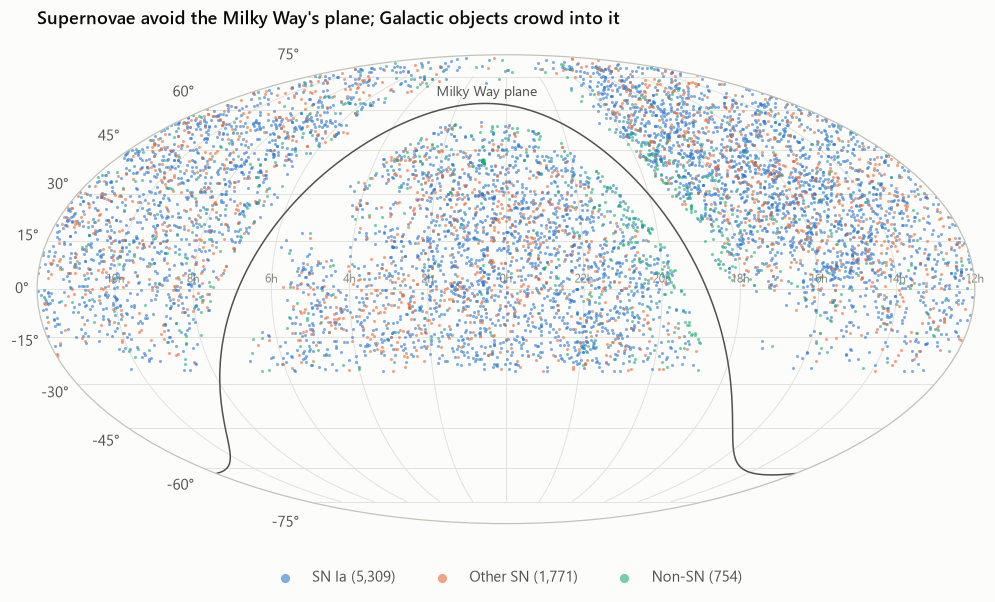

In [8]:
from astropy.coordinates import SkyCoord
import astropy.units as u


def sky_xy(ra_deg, dec_deg):
    """RA/Dec in degrees -> Mollweide x/y in radians.
    Astronomers draw RA increasing to the LEFT (as seen looking up), hence the minus sign."""
    ra = np.remainder(np.asarray(ra_deg) + 180, 360) - 180       # wrap to -180..180
    return -np.radians(ra), np.radians(np.asarray(dec_deg))


# The plane of the Milky Way (galactic latitude b = 0) as a line on the sky
plane = SkyCoord(l=np.linspace(0, 360, 721) * u.deg, b=np.zeros(721) * u.deg, frame="galactic").icrs
px_, py_ = sky_xy(plane.ra.deg, plane.dec.deg)
order = np.argsort(px_)
px_, py_ = px_[order], py_[order]

fig = plt.figure(figsize=(11, 5.6))
ax = fig.add_subplot(projection="mollweide")
for cls in CLASS3_ORDER:                                      # draw Non-SN last so it isn't hidden
    sub = classified[classified["class3"] == cls]
    x, y = sky_xy(sub["ra_deg"], sub["dec_deg"])
    ax.scatter(x, y, s=4, color=CLASS3_COLORS[cls], alpha=0.6, linewidths=0, label=f"{cls} ({len(sub):,})")
ax.plot(px_, py_, color=INK_2, linewidth=1)
ax.annotate("Milky Way plane", xy=sky_xy(13, 66), color=INK_2, fontsize=9, ha="center")

ticks = np.arange(-150, 181, 30)
ax.set_xticks(np.radians(ticks))
ax.set_xticklabels([f"{int(((-t) % 360) / 15)}h" for t in ticks], color=MUTED, fontsize=8)
ax.set_title("Supernovae avoid the Milky Way's plane; Galactic objects crowd into it", pad=20)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.16), ncols=3, markerscale=3)
ztf_style.save(fig, "02_sky_map");

**What it shows:**
* There's a **big empty area at the bottom**. Palomar is in the northern hemisphere and ZTF can't see below a declination of about −30°.
* Supernovae (blue/orange) are spread fairly evenly *except* in a band along the Milky Way plane. Dust in our Galaxy blocks the light of distant galaxies there, and the crowded star fields make detection harder.
* Non-supernovae (aqua: mostly cataclysmic variables) **cluster towards the plane**, because they're stars in our own Galaxy.

The map shows this qualitatively. A histogram of |b| (distance from the plane in degrees) puts numbers on it. If objects were spread uniformly over the sky, the distribution of |b| would follow cos(b), because there's more sky near the equator of any spherical coordinate system:

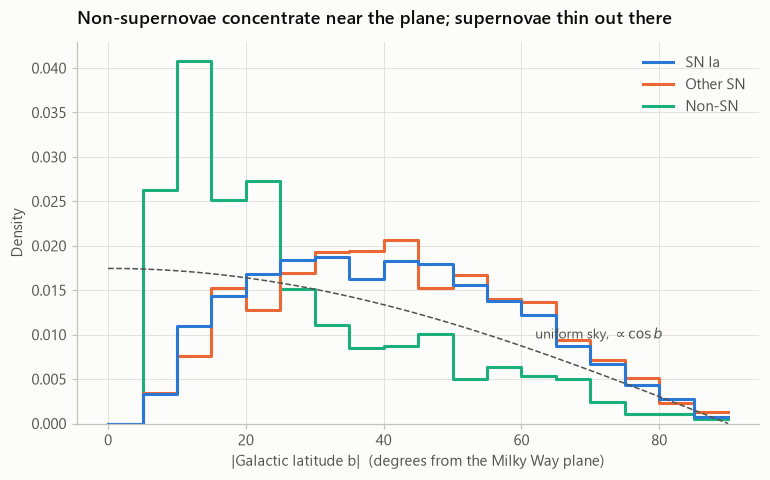

In [9]:
classified["abs_b"] = classified["b"].abs()

fig, ax = plt.subplots()
sns.histplot(data=classified, x="abs_b", hue="class3", hue_order=CLASS3_ORDER, palette=CLASS3_COLORS,
             stat="density", common_norm=False, element="step", fill=False, bins=np.arange(0, 91, 5),
             linewidth=2, ax=ax)
b_grid = np.linspace(0, 90, 100)
ax.plot(b_grid, np.cos(np.radians(b_grid)) * np.pi / 180, color=INK_2, linestyle="--", linewidth=1)
ax.annotate(r"uniform sky, $\propto \cos b$", xy=(62, 0.0095), color=INK_2, fontsize=9)

ax.set_xlabel("|Galactic latitude b|  (degrees from the Milky Way plane)")
ax.set_ylabel("Density")
ax.set_title("Non-supernovae concentrate near the plane; supernovae thin out there")
sns.move_legend(ax, "upper right", title=None)
ztf_style.save(fig, "02_galactic_latitude");

**What it shows:**
* **Nothing at all has |b| < 7°.** That's a deliberate selection cut: BTS skips the crowded Galactic plane. Notice how an edge this sharp shows up in a histogram but not in `describe()` unless you look at the minimum.
* Both supernova classes fall short of the uniform-sky curve below |b| ≈ 20°, where Galactic dust dims the galaxies behind it. They sit *above* the curve at mid-latitudes simply because each curve has to integrate to 1.
* Non-SN peak sharply at low |b|.

**For ML:** sky position is known the moment a transient is detected, so **|b| is a legitimate feature**. Being close to the plane makes a non-supernova more likely.

**A note on seaborn:** `sns.histplot(data=..., x=..., hue=...)` did the grouping, colouring and legend in one call. That's seaborn's main advantage over plain matplotlib: give it a **tidy DataFrame** (one row per observation, one column per variable) and name the columns.
* `common_norm=False` normalises each class separately, so small classes stay visible next to big ones.
* `element="step", fill=False` draws outlines, which can overlap without hiding each other.

## 5 · Distributions: how fast do transients rise and fade?

**Question:** Do different classes have different light-curve timescales? This is likely to be the most useful information for a classifier.

Only *measured* values are used here (not lower limits), and a **log scale** is needed because timescales range from under a day to hundreds of days.

5,694 classified objects with measured rise AND fade


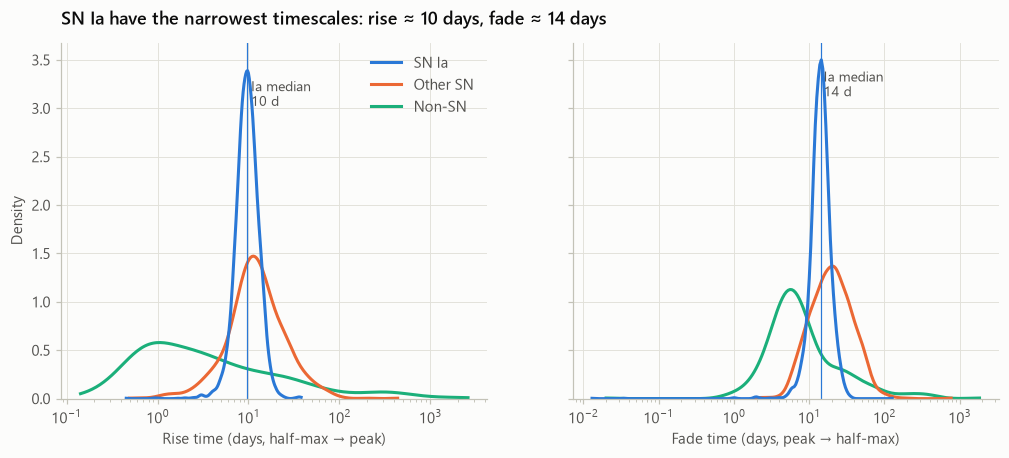

In [10]:
measured = classified[~classified["rise_is_limit"] & ~classified["fade_is_limit"]
                      & (classified["rise"] > 0) & (classified["fade"] > 0)]
print(f"{len(measured):,} classified objects with measured rise AND fade")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, col, label in zip(axes, ["rise", "fade"], ["Rise time (days, half-max → peak)", "Fade time (days, peak → half-max)"]):
    sns.kdeplot(data=measured, x=col, hue="class3", hue_order=CLASS3_ORDER, palette=CLASS3_COLORS,
                common_norm=False, log_scale=True, linewidth=2, cut=0, ax=ax, legend=(col == "rise"))
    ia_median = measured.loc[measured["is_ia"] == True, col].median()
    ax.axvline(ia_median, color=IA, linewidth=0.8)
    ax.annotate(f"Ia median\n{ia_median:.0f} d", xy=(ia_median * 1.1, ax.get_ylim()[1] * 0.85), color=INK_2, fontsize=9)
    ax.set_xlabel(label)
axes[0].set_title("SN Ia have the narrowest timescales: rise ≈ 10 days, fade ≈ 14 days")
sns.move_legend(axes[0], "upper right", title=None)
ztf_style.save(fig, "02_rise_fade_kde");

**What it shows:**
* **SN Ia have the narrowest timescale distributions.** They are physically similar explosions (a white dwarf reaching a critical mass), so they look alike.
* **Other SNe** rise at about the same speed but **fade more slowly** on average. Many SN II have a long "plateau" phase.
* **Non-SN** split into very fast objects (CV outbursts that rise in about a day) and very slow ones (AGN variability over months).

A **KDE** (kernel density estimate) is a smoothed histogram. It's easier to compare overlapping groups with, but it can invent smoothness that isn't in the data. Check it against a histogram when in doubt.

## 6 · Box plots: Type Ia as "standard candles"

**Question:** How much does the *true* peak brightness (absolute magnitude) vary within each class?

`peakabs` is only available where there is a redshift. A box plot summarises each group: the box spans the middle 50% of values, the line inside is the median and the whiskers show the spread.

,IQR (mag)
subclass,
SN Ia,0.52
TDE,1.09
SLSN,1.12
SN Ib/c,1.24
SN II,1.29
SN peculiar,1.41


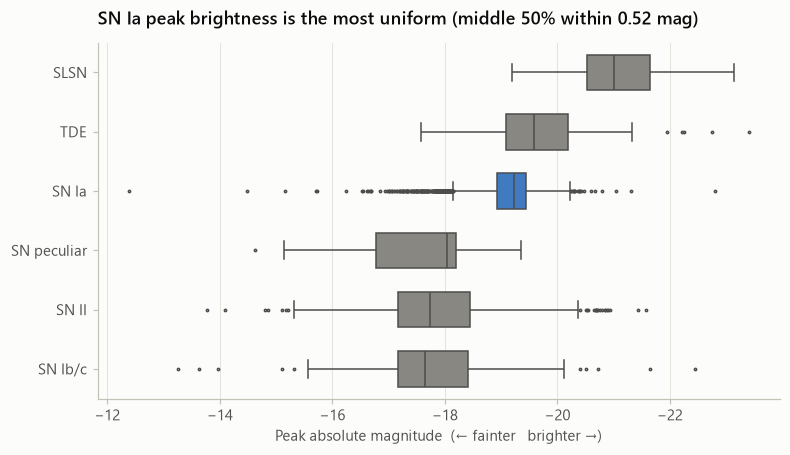

In [11]:
has_abs = classified[classified["peakabs"].notna()]
keep = has_abs["subclass"].value_counts()
keep = keep[(keep >= 15) & (keep.index != "CV / nova")].index     # novae (~-7 mag) would squash the axis
box_data = has_abs[has_abs["subclass"].isin(keep)]
box_order = box_data.groupby("subclass")["peakabs"].median().sort_values().index

fig, ax = plt.subplots(figsize=(8, 4.2))
sns.boxplot(data=box_data, x="peakabs", y="subclass", order=box_order, hue="subclass",
            palette={s: (IA if s == "SN Ia" else MUTED) for s in box_order},
            width=0.6, fliersize=1.5, linewidth=1, ax=ax, legend=False)
ax.invert_xaxis()                                   # astronomers' convention: brighter to the right
ax.set_xlabel("Peak absolute magnitude  (← fainter   brighter →)")
ax.set_ylabel("")
ax.grid(axis="y", visible=False)

iqr = box_data.groupby("subclass")["peakabs"].quantile([0.25, 0.75]).unstack().diff(axis=1).iloc[:, -1]
ax.set_title(f"SN Ia peak brightness is the most uniform (middle 50% within {iqr['SN Ia']:.2f} mag)")
ztf_style.save(fig, "02_peakabs_box");

iqr.sort_values().round(2).rename("IQR (mag)").to_frame()

**What it shows:** SN Ia have one of the **narrowest** spreads in peak luminosity of all the classes, centred near **−19.2 mag**. That's why Ia are called **standard candles**: if you know how bright something really is, how bright it *looks* tells you how far away it is. Measuring distances this way with Ia led to the discovery of the accelerating expansion of the Universe (Nobel Prize 2011).

**For ML:** `peakabs` looks like a great feature. **But it needs a redshift, and the redshift comes from the same spectrum that gave the classification.** At prediction time for a new transient it won't exist. Notebook 3 goes into this.

## 7 · The Hubble diagram

Since SN Ia all have about the same luminosity, their apparent brightness should depend only on distance (redshift) in a predictable way. astropy's cosmology module gives the predicted **distance modulus** μ(z), and a standard candle of absolute magnitude M should appear at magnitude m = M + μ(z).

**Question:** Do the BTS supernovae follow that prediction?

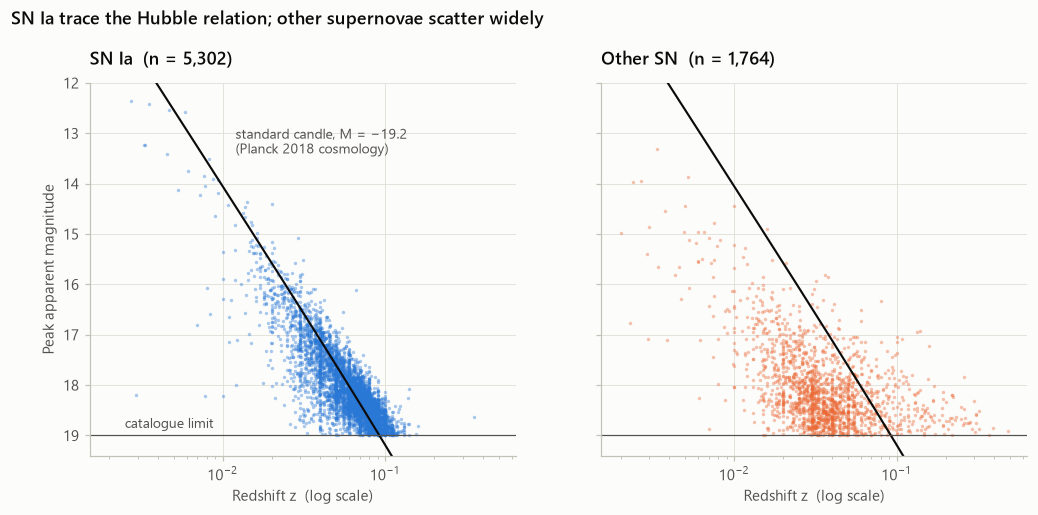

In [12]:
from astropy.cosmology import Planck18

z_grid = np.geomspace(0.002, 0.25, 200)
model_mag = -19.2 + Planck18.distmod(z_grid).value

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True, sharey=True)
panels = [("SN Ia", classified[classified["class3"] == "SN Ia"]),
          ("Other SN", classified[classified["class3"] == "Other SN"])]
for ax, (name, sub) in zip(axes, panels):
    sub = sub[sub["redshift"].notna()]
    ax.scatter(sub["redshift"], sub["peakmag"], s=5, color=CLASS3_COLORS[name], alpha=0.4, linewidths=0)
    ax.plot(z_grid, model_mag, color=INK, linewidth=1.4)
    ax.axhline(19.0, color=INK_2, linewidth=0.8)
    ax.set_title(f"{name}  (n = {len(sub):,})")
    ax.set_xlabel("Redshift z  (log scale)")
axes[0].set_xscale("log")
axes[0].set_ylim(19.4, 12)                         # inverted: brighter is up
axes[0].set_ylabel("Peak apparent magnitude")
axes[0].annotate("standard candle, M = −19.2\n(Planck 2018 cosmology)", xy=(0.012, 13.4), color=INK_2, fontsize=9)
axes[0].annotate("catalogue limit", xy=(0.0025, 18.85), color=INK_2, fontsize=9)
fig.suptitle("SN Ia trace the Hubble relation; other supernovae scatter widely", x=0.06, y=1.03, ha="left",
             fontsize=12, fontweight="semibold")
ztf_style.save(fig, "02_hubble_diagram");

**What it shows:**
* SN Ia (left) follow the cosmological prediction closely over a factor of ~100 in distance. This one plot captures why Ia matter to cosmology.
* Other SNe (right) scatter much more, and mostly lie *below* the curve because they're fainter. The few far *above* it at high redshift are superluminous supernovae.
* Both samples are **cut off at magnitude 19**. At high redshift only the *brightest* Ia make it into the catalogue. That's called **Malmquist bias**, and the next plot shows it directly:

,median,count
z_bin,,
"(0.0, 0.02]",-18.57,138
"(0.02, 0.04]",-18.82,810
"(0.04, 0.06]",-19.04,1383
"(0.06, 0.08]",-19.27,1812
"(0.08, 0.1]",-19.46,1003
"(0.1, 0.13]",-19.67,148
"(0.13, 0.2]",-20.40,7


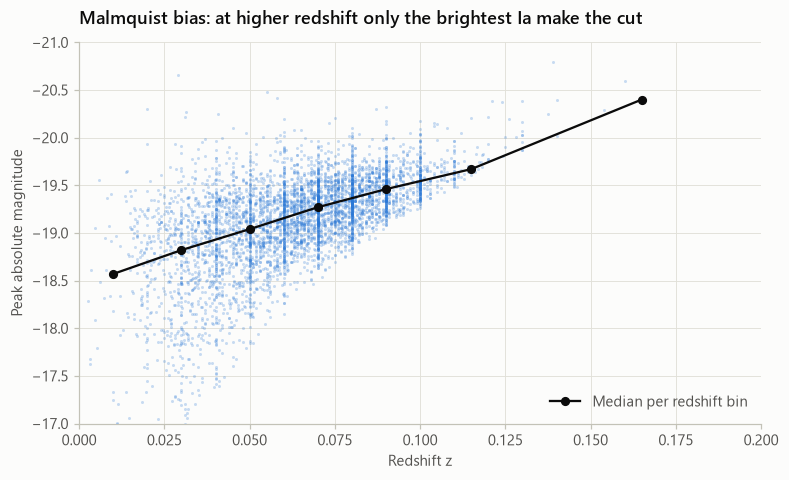

In [13]:
ia = classified[(classified["is_ia"] == True) & classified["peakabs"].notna()].copy()
ia["z_bin"] = pd.cut(ia["redshift"], bins=[0, 0.02, 0.04, 0.06, 0.08, 0.10, 0.13, 0.2])
trend = ia.groupby("z_bin", observed=True)["peakabs"].agg(["median", "count"])

fig, ax = plt.subplots()
ax.scatter(ia["redshift"], ia["peakabs"], s=4, color=IA, alpha=0.25, linewidths=0)
mids = [interval.mid for interval in trend.index]
ax.plot(mids, trend["median"], color=INK, marker="o", markersize=5, linewidth=1.5, label="Median per redshift bin")
ax.set_xlim(0, 0.2)
ax.set_ylim(-17, -21)
ax.set_xlabel("Redshift z")
ax.set_ylabel("Peak absolute magnitude")
ax.set_title("Malmquist bias: at higher redshift only the brightest Ia make the cut")
ax.legend(loc="lower right")
ztf_style.save(fig, "02_malmquist_bias");
trend.round(2)

**What it shows:** the median Ia *appears* to get brighter with distance. Ia don't really change; the faint ones at large distances simply drop below magnitude 19 and vanish from the sample. Here the dataset's selection effects are showing up as a pattern that isn't real. **Always ask how a dataset was selected before believing a trend in it.**

*Bonus observation:* the vertical stripes at z = 0.04, 0.05, 0.06, ... are redshifts recorded to only **two decimal places**. They were probably estimated by matching the supernova spectrum to templates rather than measured precisely from galaxy lines. Precision varies from row to row, and plots like this reveal it.

## 8 · Scatter plots and small multiples: rise vs fade

**Question:** Do classes separate in the 2-D space of rise time *and* fade time together?

With thousands of overlapping points, one scatter plot with three colours becomes a mess. **Small multiples** work better: one panel per class, with all other objects drawn in light grey behind for context.

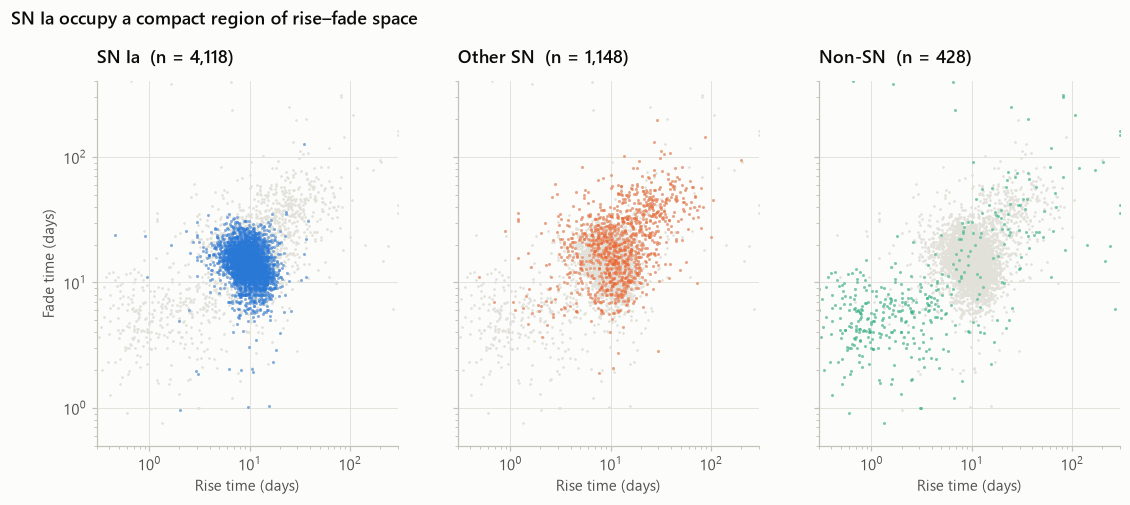

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.3), sharex=True, sharey=True)
for ax, cls in zip(axes, CLASS3_ORDER):
    sub = measured[measured["class3"] == cls]
    ax.scatter(measured["rise"], measured["fade"], s=3, color=GRID, linewidths=0)       # context
    ax.scatter(sub["rise"], sub["fade"], s=4, color=CLASS3_COLORS[cls], alpha=0.5, linewidths=0)
    ax.set_title(f"{cls}  (n = {len(sub):,})")
    ax.set_xlabel("Rise time (days)")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlim(0.3, 300)
axes[0].set_ylim(0.5, 400)
axes[0].set_ylabel("Fade time (days)")
fig.suptitle("SN Ia occupy a compact region of rise–fade space", x=0.06, y=1.03, ha="left",
             fontsize=12, fontweight="semibold")
ztf_style.save(fig, "02_rise_vs_fade");

**What it shows:** Ia form a **tight clump** around a rise of ~10 days and a fade of ~14 days. Other SNe overlap the clump but spread towards longer fade times, and non-SN are spread widely. The Ia clump is useful but it **overlaps** with other SNe, so rise and fade alone won't be a perfect classifier.

## 9 · Heatmaps: correlations between features

A correlation matrix shows how strongly each pair of numeric columns moves together, from −1 (opposite) through 0 (unrelated) to +1 (together). **Spearman** correlation uses ranks, which makes it robust to outliers and long tails like the timescales here.

The colour scale is **diverging**: blue for negative, red for positive, grey for zero. Zero should look like "nothing".

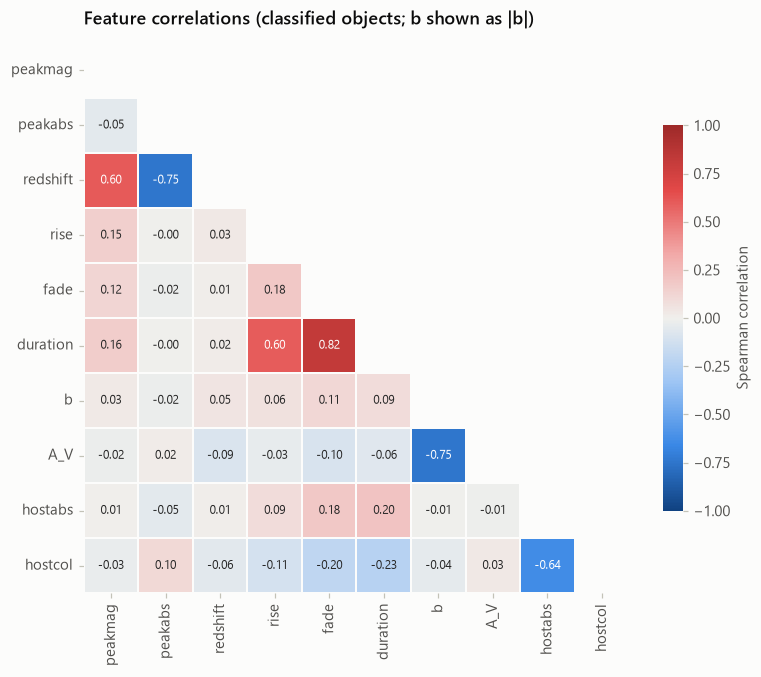

In [15]:
features = ["peakmag", "peakabs", "redshift", "rise", "fade", "duration", "b", "A_V", "hostabs", "hostcol"]
corr = classified[features].assign(b=classified["b"].abs()).corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))          # hide the mirror-image upper half

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, mask=mask, cmap="ztf_diverging", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"fontsize": 8}, linewidths=1, linecolor=ztf_style.SURFACE,
            cbar_kws={"shrink": 0.7, "label": "Spearman correlation"}, ax=ax)
ax.grid(False)
ax.set_title("Feature correlations (classified objects; b shown as |b|)")
ztf_style.save(fig, "02_correlation_heatmap");

**What it shows:**
* `duration`, `rise` and `fade` are strongly correlated. That's expected, since `duration = rise + fade` by definition. Correlated features carry **redundant** information.
* `peakabs` and `redshift` are strongly negatively correlated: farther objects are intrinsically brighter. That's the **Malmquist bias** again, not physics.
* `|b|` and `A_V` are negatively correlated: there's more Galactic dust near the plane.
* `hostabs` and `hostcol` are related: brighter galaxies tend to be redder, a well-known property of galaxies.

## 10 · Pair plots: everything against everything

`sns.pairplot` draws every pair of variables as a scatter plot, with each variable's distribution on the diagonal. It's a quick way to see several features at once. On large datasets, plot a random **sample** to keep it fast and readable.

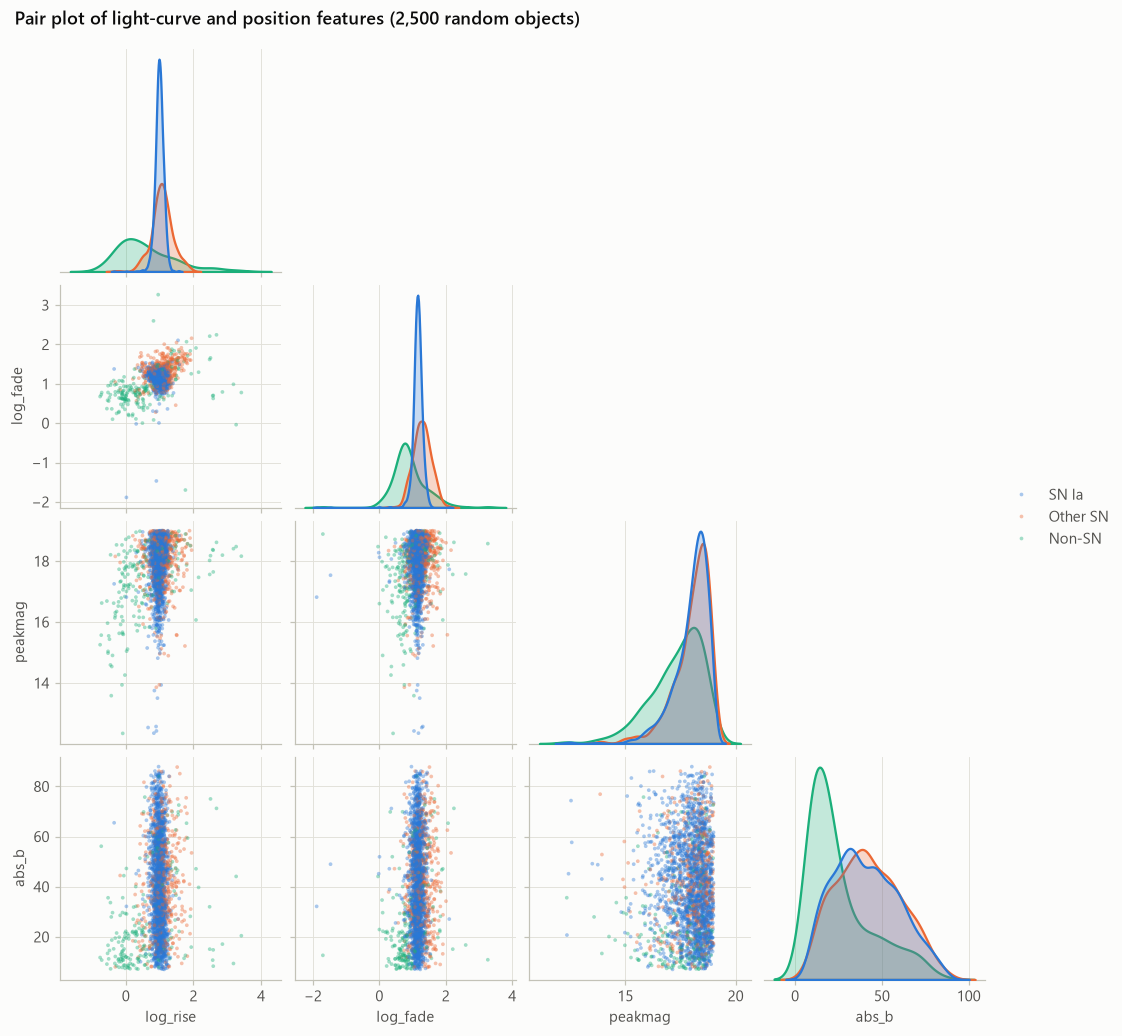

In [16]:
pair = measured.sample(2500, random_state=0).assign(
    log_rise=lambda d: np.log10(d["rise"]),
    log_fade=lambda d: np.log10(d["fade"]),
    abs_b=lambda d: d["b"].abs(),
)
grid = sns.pairplot(pair, vars=["log_rise", "log_fade", "peakmag", "abs_b"], hue="class3",
                    hue_order=CLASS3_ORDER, palette=CLASS3_COLORS, corner=True, height=2.3,
                    plot_kws=dict(s=6, alpha=0.4, linewidth=0), diag_kws=dict(common_norm=False, linewidth=1.5))
grid.figure.suptitle("Pair plot of light-curve and position features (2,500 random objects)",
                     x=0.02, ha="left", y=1.02, fontsize=12, fontweight="semibold")
grid._legend.set_title(None)
ztf_style.save(grid.figure, "02_pairplot");

**What it shows:** no single panel separates the classes cleanly, but each feature pulls in a slightly different direction. That's what a machine-learning model is for: **combining many weak signals** into a stronger one.

## 11 · Bonus: interactive plots with plotly

Static plots are best for reports. For *exploring*, being able to **hover over a point and see which object it is** is very useful. `plotly.express` has an API similar to seaborn's (`data`, `x`, `y`, `color`) but produces interactive charts. Try hovering, zooming (drag a box) and clicking legend entries to hide classes.

In [ ]:
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "plotly_mimetype+notebook_connected"   # works in VS Code, JupyterLab and HTML export

fig = px.scatter(
    measured, x="rise", y="fade", color="class3",
    color_discrete_map=CLASS3_COLORS, category_orders={"class3": CLASS3_ORDER},
    log_x=True, log_y=True, opacity=0.6,
    hover_name="ZTFID", hover_data={"IAUID": True, "type": True, "peakmag": ":.2f", "redshift": ":.3f",
                                    "rise": ":.1f", "fade": ":.1f", "class3": False},
    labels={"rise": "Rise time (days)", "fade": "Fade time (days)", "class3": ""},
    title="Rise vs fade time: hover over any point to identify it",
    template="simple_white", height=520,
)
fig.update_traces(marker=dict(size=5, line=dict(width=0)))
fig.show()

## Summary: what I learned

**About plotting**
* matplotlib's `fig, ax = plt.subplots()` plus `ax.method()` calls gives full control. Make the title state the **finding**, not just name the variables.
* seaborn makes grouped statistical plots from a tidy DataFrame in one call: `data=`, `x=`, `y=`, `hue=`.
* Pick the chart for the question: histogram/KDE for distributions, bars for categories, lines for time, scatter for relationships, heatmap for a matrix, small multiples when one plot gets overcrowded.
* Keep a fixed colour per class, grey out what isn't the story, use log scales for quantities spanning orders of magnitude, and never put two different y-scales on one axis.

**About the data**
1. The catalogue is **magnitude-limited** (cut at 19, incomplete beyond ~17.5) and excludes |b| < 7°, so it's biased towards intrinsically bright objects.
2. **SN Ia are 68%** of classified objects, so the baseline accuracy to beat is 68%.
3. **Galactic objects cluster near the Milky Way plane**, so |b| is a useful, legitimate feature.
4. **SN Ia have characteristic, narrow timescales** (rise ~10 d, fade ~14 d), the most useful photometric signal.
5. **SN Ia are standard candles** (peak M ≈ −19.2 with a small spread), but absolute magnitude needs a spectroscopic redshift.
6. **Selection effects create false trends** (Malmquist bias), so always ask how the data was selected.

## Exercises
1. Remake the rise-time KDE using `subclass` instead of `class3`, for SN Ia, SN II and SN Ib/c only. Which two are hardest to tell apart?
2. Plot `peakmag` histograms separately for `peakfilt == "g"` and `"r"`. Is there a difference?
3. Make a sky map in **galactic coordinates** (hint: `SkyCoord(...).galactic.l` and `.b`). The plane becomes a horizontal line.
4. Plot the *fraction* of objects that are Ia in bins of fade time (`pd.cut` + `groupby` + `mean`). Where is the "most Ia-like" fade time?

## Exercise 1 · Rise time by supernova subtype

**Question:** If supernovae are split by `subclass` instead of the broad `class3`, which two of SN Ia, SN II and SN Ib/c are hardest to tell apart by rise time alone?

This is the same KDE as section 5 with two changes: `hue="subclass"`, and only these three subtypes are kept. SN Ia keeps its blue. SN II gets orange, the colour already used for other supernovae. SN Ib/c gets violet, because aqua means "non-supernova" everywhere else in this notebook.

In [ ]:
SN_SUBTYPE_COLORS = {"SN Ia": IA, "SN II": ztf_style.NOT_IA, "SN Ib/c": ztf_style.CYCLE[6]}
sn = measured[measured["subclass"].isin(SN_SUBTYPE_COLORS)]

fig, ax = plt.subplots()
sns.kdeplot(data=sn, x="rise", hue="subclass", hue_order=list(SN_SUBTYPE_COLORS), palette=SN_SUBTYPE_COLORS,
            common_norm=False, log_scale=True, linewidth=2, cut=0, ax=ax)
ax.set_xlabel("Rise time (days, half-max → peak)")
ax.set_title("SN II and SN Ib/c rise times overlap most; SN Ia are the narrowest")
sns.move_legend(ax, "upper right", title=None)
ztf_style.save(fig, "02_ex1_rise_by_subtype");

sn.groupby("subclass")["rise"].describe()[["count", "25%", "50%", "75%"]].round(1)

In [ ]:
# How much do two distributions overlap? Bin each on the same log grid, turn counts into fractions,
# and add up the smaller of the two in every bin: 1 = identical, 0 = completely separate.
bins = np.geomspace(0.3, 500, 41)
shares = {name: np.histogram(rise, bins=bins)[0] / len(rise) for name, rise in sn.groupby("subclass")["rise"]}
pairs = [("SN Ia", "SN II"), ("SN Ia", "SN Ib/c"), ("SN II", "SN Ib/c")]
pd.Series({f"{a} vs {b}": np.minimum(shares[a], shares[b]).sum() for a, b in pairs}, name="overlap").round(2)

**What it shows:**
* **SN II and SN Ib/c are the hardest pair to tell apart** (overlap 0.80). Both are core-collapse supernovae, from massive stars whose cores collapse, so their rise times look alike.
* **SN Ia and SN Ib/c come next** (0.75). Ib/c peak at almost the same rise time as Ia (median 10.9 d vs 9.7 d), but their distribution is wider. This is a known problem in practice: Ib/c are the subtype most often confused with Ia.
* **SN Ia vs SN II separate best** (0.59), mainly because many SN II rise slowly and give a long tail past 20 days.

**For ML:** rise time on its own mostly tells Ia apart from SN II. Separating Ia from Ib/c will need other features, such as fade time, colour or host galaxy.

## Exercise 2 · Peak magnitude in the g and r filters

**Question:** ZTF observes through a green (**g**) and a red (**r**) filter, and `peakfilt` records which one the peak magnitude was measured in. Do transients that peak in g look different from those that peak in r?

There are more r peaks (6,044) than g peaks (5,160), so the histograms use `stat="density"` with `common_norm=False`. That compares the *shapes*, not the totals. Green and red are the natural colours for these filters, but some colour-blind readers can't tell them apart, so each line is also labelled directly.

In [ ]:
FILTER_COLORS = {"g": ztf_style.CYCLE[5], "r": ztf_style.CYCLE[7]}     # green and red, labelled directly as well

fig, ax = plt.subplots()
sns.histplot(data=df, x="peakmag", hue="peakfilt", hue_order=list(FILTER_COLORS), palette=FILTER_COLORS,
             stat="density", common_norm=False, element="step", fill=False, bins=np.arange(12, 19.05, 0.1),
             linewidth=2, ax=ax)
ax.annotate("peaked in g", xy=(16.45, 0.13), color=INK_2, fontsize=9, ha="right")
ax.annotate("peaked in r", xy=(18.75, 1.2), color=INK_2, fontsize=9, ha="right")

medians = df.groupby("peakfilt")["peakmag"].median()
ax.set_xlim(14, 19.1)                               # only a handful of objects are brighter than 14
ax.set_xlabel("Peak apparent magnitude  (← brighter   fainter →)")
ax.set_ylabel("Density")
ax.set_title(f"Peaks in g are slightly brighter than peaks in r (medians {medians['g']:.2f} vs {medians['r']:.2f})")
sns.move_legend(ax, "upper left", title="Peak filter")
ztf_style.save(fig, "02_ex2_peakmag_by_filter");

# Share of g vs r peaks in each magnitude bin: normalize="index" makes each row add up to 1
pd.crosstab(pd.cut(df["peakmag"], [12, 16, 17, 17.5, 18, 18.5, 19]), df["peakfilt"], normalize="index").round(2)

In [ ]:
# Class mix within each filter: normalize="columns" makes each column add up to 1
pd.crosstab(classified["class3"], classified["peakfilt"], normalize="columns").reindex(CLASS3_ORDER).round(2)

**What it shows:** yes, there's a small difference.
* Transients that peak in **g are about 0.15 mag brighter** (median 18.35 vs 18.50). The g histogram has more objects on the bright side, and the r histogram piles up more steeply against the magnitude-19 limit.
* The tables show the same thing. Brighter than magnitude 16, about two thirds of objects peak in g. In the faintest bin (18.5–19), about 60% peak in r.
* The **class mix differs too**. 75% of classified g-peak objects are SN Ia, against 61% of r-peak objects. Other SNe make up a much bigger share of the r peaks (32% vs 13%).

**For ML:** a g magnitude and an r magnitude aren't the same measurement, so `peakmag` mixes two slightly different scales. `peakfilt` also differs between classes, so it could be a small but legitimate feature, since it's known from the light curve alone.

## Exercise 4 · What fraction are SN Ia, by fade time?

**Question:** Where is the "most Ia-like" fade time?

The recipe is `pd.cut` + `groupby` + `mean`:
1. `pd.cut` puts each object's fade time into a bin. The bins are log-spaced because fade times run from about a day to hundreds of days.
2. `groupby` on those bins gathers the objects in each one.
3. `mean` of the True/False `is_ia` column gives the **fraction that are Ia** in each bin, the same trick as `ia_share` in section 2.

Bins with fewer than 20 objects are dropped. The error bars show the binomial uncertainty √(p(1−p)/n), which shrinks as a bin holds more objects. The dashed line is the Ia fraction among all objects with a measured fade time, which a fade-time cut has to beat.

In [ ]:
from matplotlib.ticker import NullFormatter, PercentFormatter

fade_bins = np.geomspace(1, 300, 21)                 # log-spaced: fade times span 1 to 300 days
by_fade = (measured.groupby(pd.cut(measured["fade"], fade_bins), observed=True)["is_ia"]
                   .agg(ia_fraction="mean", n="count"))
by_fade = by_fade[by_fade["n"] >= 20]                # fractions from a handful of objects are too noisy to plot
by_fade["mid"] = [np.sqrt(b.left * b.right) for b in by_fade.index]      # geometric centre of each log bin
by_fade["err"] = np.sqrt(by_fade["ia_fraction"] * (1 - by_fade["ia_fraction"]) / by_fade["n"])

baseline = measured["is_ia"].mean()
best = by_fade["ia_fraction"].idxmax()

fig, ax = plt.subplots()
ax.axhline(baseline, color=INK_2, linewidth=0.8, linestyle="--")
ax.annotate(f"all measured objects: {baseline:.0%} Ia", xy=(1.7, baseline + 0.03), color=INK_2, fontsize=9)
ax.errorbar(by_fade["mid"], by_fade["ia_fraction"], yerr=by_fade["err"], color=IA, marker="o", markersize=5,
            linewidth=2, capsize=0, elinewidth=1)
ax.annotate(f"{by_fade.loc[best, 'ia_fraction']:.0%} Ia at\n{best.left:.0f}–{best.right:.0f} days",
            xy=(by_fade.loc[best, "mid"], by_fade.loc[best, "ia_fraction"]), xytext=(24, 0.92), color=INK_2, fontsize=9,
            arrowprops=dict(arrowstyle="->", color=INK_2, linewidth=0.8))

ax.set_xscale("log")
ax.set_xlim(1.5, 90)
ax.set_xticks([2, 3, 5, 10, 20, 30, 50], labels=["2", "3", "5", "10", "20", "30", "50"])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Fade time (days, peak → half-max)")
ax.set_ylabel("Fraction that are SN Ia")
ax.set_title("Transients that fade in about two weeks are 90% SN Ia")
ztf_style.save(fig, "02_ex4_ia_fraction_by_fade");

by_fade[["ia_fraction", "n"]].round(2)

**What it shows:**
* The **most Ia-like fade time is 13–17 days**: 90% of the 1,884 objects in that bin are SN Ia. Between about 10 and 23 days the fraction stays above the 72% baseline.
* **Fast faders** (under ~6 days) are mostly not Ia. They're mainly CVs and novae.
* **Slow faders** are almost never Ia. Above ~30 days the fraction falls to 10%, and above 40 days it's 0%. These are mostly SN II with their long plateaus, plus AGN and superluminous supernovae.
* The error bars are tiny in the middle bins, which hold over a thousand objects each, and large in the sparse bins at the edges.

**For ML:** a single cut on fade time already gives a purer Ia sample than the 72% baseline. But the window is wide, and it still contains 10–15% non-Ia, so a classifier needs to combine fade time with other features.